# 02 — Le téléchargement complet et la couche bronze

Le notebook 01 nous a convaincus que le projet était faisable. Ici, on télécharge **toutes** les données utiles, on les
range dans la couche **bronze**, puis on s'attaque au premier vrai risque du projet : l'humidité mesurée par les sondes
bon marché.

Le plan du notebook :

1. les paires finales et leurs deux bandes de distance ;
2. le plan de téléchargement ;
3. ce qu'on a réellement reçu (volumes, fichiers absents, échecs, durée) ;
4. ce que le contrat de la couche bronze a détecté ;
5. les stations de référence et leur type ;
6. la météo officielle, qui sert de secours pour l'humidité, et son horloge ;
7. l'humidité saturée des sondes : par type, par mois, selon l'âge, et la preuve que c'est une panne ;
8. les capteurs qui ont déménagé pendant la période.

Un peu de vocabulaire :

- **Architecture médaillon** : les données passent par des couches de plus en plus propres. `raw` contient les fichiers
  tels qu'on les a reçus (supprimés ensuite), **`bronze`** les mêmes valeurs mais typées et en Parquet, `silver` les
  données nettoyées et horaires (notebook 03), `gold` les paires prêtes pour le modèle (notebook 05).
- **Parquet** : un format de fichier en colonnes, compressé (ici avec zstd), très rapide à relire.
- **Contrat de données** (un schéma **Pandera**) : la liste des colonnes attendues et de leur type. Un fichier qui ne le
  respecte pas fait échouer la conversion, au lieu de passer en silence.
- **Manifeste** : un journal avec une ligne par unité de travail terminée. Il permet de **reprendre** un téléchargement
  interrompu et de savoir exactement ce qu'on a reçu.
- **Unité** : pour Sensor.Community, un capteur pendant un mois (une trentaine de fichiers d'un jour).
- **Paire** et **bande** : un capteur associé à sa station, à moins de 1,5 km (`near`) ou entre 1,5 et 3 km (`far`).

Le code est dans `src/aircalib/ingest/`. Les commandes sont `python -m aircalib download` puis `python -m aircalib bronze`
(avec `--sample` pour un essai rapide sur 10 capteurs par pays et un mois).

## 0. Préparation

On charge la configuration et les modules. Avec `SAMPLE = True`, le notebook tournerait sur l'échantillon
(`data/sample/`) au lieu du volume complet : le code est le même, seuls les dossiers et la période changent.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.ingest.download import sc_manifests
from aircalib.ingest.manifest import Manifest
from aircalib.ingest.report import folder_bytes, sensor_community_summary
from aircalib.schemas import bronze as contracts
from aircalib.transform import humidity as hum
from aircalib.transform.hourly import offset_correlation, ten_minute_means
from aircalib.transform.pairing import haversine_km
from aircalib.transform.positions import position_history

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
B = settings.paths.bronze
REF = B / "reference"
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAT = settings.humidity.saturation_pct
pl.Config.set_engine_affinity("streaming")  # hundreds of millions of rows: stream instead of loading
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(14)
pl.Config.set_tbl_width_chars(160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
root = settings.paths.data_dir.parent
print("période :", settings.period.start, "→", settings.period.end, "| bronze :", B.relative_to(root))

période : 2024-01-01 → 2025-12-31 | bronze : data/bronze


## 1. Les paires finales : un capteur, une station, deux bandes de distance

On relit la table des paires (`bronze/reference/pairs.parquet`). Chaque SDS011 extérieur y est associé à **une seule**
station : la plus proche qui a des heures vérifiées pendant que le capteur fonctionne, à moins de 3 km. On distingue deux
bandes : `near` (≤ 1,5 km), où l'on apprendra en Allemagne, et `far` (1,5–3 km), qui servira de test « distance ».

Pourquoi regarder si une même station apparaît dans les deux bandes ? Parce que le modèle sera évalué en séparant les
stations : une station et tous ses capteurs tombent dans le même groupe (ce qu'on appelle une **validation croisée
groupée**, *GroupKFold*). Si une station servait à la fois à l'apprentissage et au test, le modèle aurait déjà vu sa
pollution locale et paraîtrait meilleur qu'il ne l'est. C'est une **fuite d'information**, et c'est exactement ce qu'on
veut éviter.

In [2]:
pairs = pl.read_parquet(REF / "pairs.parquet")
assert pairs["sensor_id"].is_unique().all()
by_band = (
    pairs.group_by("country", "distance_band")
    .agg(
        paires=pl.len(),
        stations=pl.col("station_code").n_unique(),
        distance_médiane_km=pl.col("distance_km").median().round(2),
        part_trafic=(pl.col("station_type") == "traffic").mean().round(2),
        avec_sonde_humidité=pl.col("has_humidity").mean().round(2),
    )
    .sort("country", "distance_band", descending=[False, True])
)
near = set(pairs.filter(pl.col("distance_band") == "near")["station_code"])
far = set(pairs.filter(pl.col("distance_band") == "far")["station_code"])
print(f"stations dans les deux bandes : {len(near & far)}")
print(f"seulement near : {len(near - far)} | seulement far : {len(far - near)}")
by_band

stations dans les deux bandes : 145
seulement near : 69 | seulement far : 84


country,distance_band,paires,stations,distance_médiane_km,part_trafic,avec_sonde_humidité
str,str,u32,u32,f64,f64,f64
"""DE""","""near""",559,179,0.88,0.57,0.84
"""DE""","""far""",698,189,2.23,0.52,0.78
"""FR""","""near""",48,35,1.01,0.33,0.75
"""FR""","""far""",94,40,2.24,0.33,0.65


La distance de chaque capteur à sa station, avec la frontière entre les deux bandes :

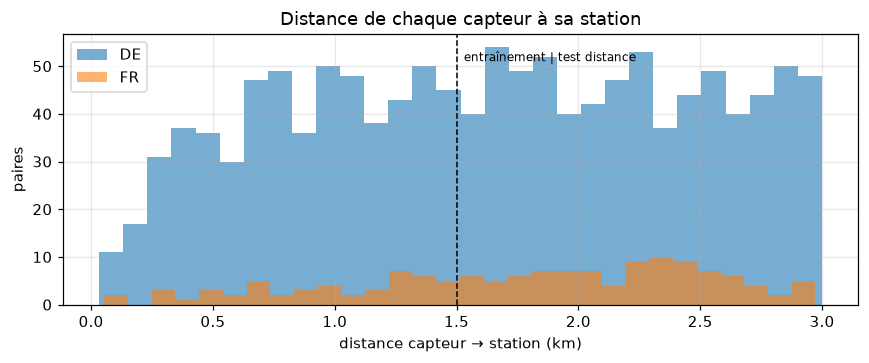

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for country, part in pairs.group_by("country", maintain_order=True):
    ax.hist(part["distance_km"], bins=30, alpha=0.6, label=country[0])
ax.axvline(settings.pairing.radius_train_km, color="k", ls="--", lw=1)
ax.text(
    settings.pairing.radius_train_km + 0.03,
    ax.get_ylim()[1] * 0.9,
    "entraînement | test distance",
    fontsize=8,
)
ax.set_xlabel("distance capteur → station (km)")
ax.set_ylabel("paires")
ax.set_title("Distance de chaque capteur à sa station")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distances_paires.png")

On a 1 399 paires SDS011, une par capteur (l'`assert` le vérifie). En Allemagne, 559 paires `near` (179 stations,
distance médiane 0,88 km) et 698 `far` (189 stations, 2,23 km) ; en France, 48 + 94 paires (35 et 40 stations). Et
surtout, **145 stations** ont des capteurs dans les deux bandes.

Sans découpage par station, la même pollution locale servirait donc à apprendre et à tester la distance. On appliquera ce
découpage à **toutes** les distances : une station ne sera jamais à la fois en apprentissage et en test. Point rassurant
au passage, la part de stations trafic change peu d'une bande à l'autre en Allemagne (57 % et 52 %), donc on ne
confondra pas l'effet de la distance avec un changement de type de station. En France, une paire sur trois seulement est
près d'une station trafic.

## 2. Le plan de téléchargement

Problème : on ne connaît l'activité de chaque capteur qu'au mois près (vu ou non le 15). Comment demander tous ses jours
utiles sans lister les 731 jours d'archive, ce qui prendrait environ 13 heures ?

Un capteur vu pour la première fois le 15 du mois $m_{\text{premier}}$ a pu démarrer juste après le 15 du mois précédent.
De même, un capteur vu pour la dernière fois en $m_{\text{dernier}}$ a pu s'arrêter juste avant le 15 du mois suivant.
On demande donc tous les jours de sa **fenêtre d'activité** :

$$
\big[\ 15_{\,m_{\text{premier}}-1} + 1\ \text{jour}\ ,\ \ 15_{\,m_{\text{dernier}}+1} - 1\ \text{jour}\ \big] \cap [\text{début}, \text{fin}]
$$

où $15_{m}$ désigne le 15 du mois $m$ et $[\text{début}, \text{fin}]$ la période d'étude. Un jour demandé mais absent du
serveur (erreur HTTP 404) n'est pas une erreur : c'est simplement un jour sans mesure.

In [4]:
units = pl.read_parquet(REF / "sensor_months.parquet")
humidity_probes = pl.read_parquet(REF / "humidity_sensors.parquet")
print(
    "sondes d'humidité par type :",
    dict(humidity_probes["sensor_type"].value_counts().sort("count", descending=True).iter_rows()),
)
units.group_by("kind").agg(
    capteurs=pl.col("sensor_id").n_unique(), unités=pl.len(), jours_demandés=pl.col("n_days").sum()
)

sondes d'humidité par type : {'dht22': 628, 'bme280': 473, 'sht31': 16, 'htu21d': 5, 'sht30': 4, 'sht85': 1}


kind,capteurs,unités,jours_demandés
str,u32,u32,i64
"""humidity""",1127,20011,596997
"""pm""",1399,25326,757010


Ce tableau, c'est le plan : capteurs, unités et jours demandés, pour les capteurs de particules et pour les sondes
d'humidité installées sur les mêmes sites. On compare ensuite avec ce qui est vraiment arrivé.

## 3. Qu'est-ce qu'on a vraiment reçu ?

On voulait un pipeline honnête, qui dise ce qu'il n'a pas pu récupérer. On relit donc les manifestes : jours demandés,
trouvés et absents, unités en échec (une unité en échec est retentée au lancement suivant, et on compte aussi celles qui
ont fini par passer), puis la durée réelle et la place sur le disque.

In [5]:
raw_manifest, bronze_manifest = sc_manifests(settings)
raw_log = pl.read_ndjson(raw_manifest.path, infer_schema_length=None)
latest = raw_manifest.frame()
summary = sensor_community_summary(latest, bronze_manifest.frame())
stamps = raw_log["recorded_at"].str.to_datetime()
hours = (stamps.max() - stamps.min()).total_seconds() / 3600
requests = int(latest["days_requested"].sum())
retried, remaining = (raw_log["status"] == "failed").sum(), (latest["status"] == "failed").sum()
print(f"échecs rencontrés puis retentés : {retried} | échecs restants : {remaining}")
rate = requests / max(hours, 1e-9) / 3600
print(f"durée Sensor.Community : {hours:.2f} h pour {requests:,} jours demandés ({rate:.0f} requêtes/s)")
print(f"jours absents (404) : {latest['days_absent'].sum() / requests:.1%}")
summary

échecs rencontrés puis retentés : 57 | échecs restants : 0
durée Sensor.Community : 3.58 h pour 1,354,007 jours demandés (105 requêtes/s)
jours absents (404) : 10.7%


kind,units_ok,units_failed,days_requested,days_found,days_absent,downloaded_mb,…,conversion_failed,rows,corrupt_files,unparsed_values,dropped_nonempty,foreign_sensor_rows,bronze_mb
str,u32,u32,i64,i64,i64,f64,…,u32,i64,i64,i64,i64,i64,f64
"""humidity""",20011,0,596997,527573,69424,2532.255139,…,0,289721376,0,1624,0,0,2223.136379
"""pm""",25326,0,757010,681157,75853,3321.214434,…,0,377950455,0,20112,0,0,2916.301773


Le même bilan pour les trois autres sources (EEA, DWD, Météo-France) et pour le disque :

In [6]:
others = []
for source, key in (
    ("eea", ("pollutant", "sampling_point")),
    ("dwd", ("filename",)),
    ("meteo_france", ("filename",)),
):
    raw = Manifest(settings.paths.raw / source / "_manifest.jsonl", key).frame()
    conv = Manifest(B / source / "_manifest.jsonl", key).frame()
    others.append(
        {
            "source": source,
            "fichiers_reçus": int((raw["status"] == "ok").sum()) if raw.height else 0,
            "échecs_téléchargement": int((raw["status"] == "failed").sum()) if raw.height else 0,
            "convertis": int((conv["status"] == "ok").sum()) if conv.height else 0,
            "échecs_conversion": int((conv["status"] == "failed").sum()) if conv.height else 0,
            "reçu_Mo": round((raw["bytes"].sum() if "bytes" in raw.columns else 0) / 1e6, 1),
            "bronze_Mo": round(folder_bytes(B / source) / 1e6, 1),
        }
    )
disk = {
    name: round(folder_bytes(path) / 1e9, 2)
    for name, path in (("raw", settings.paths.raw), ("bronze", B), ("meta", settings.paths.meta))
}
print("espace disque (Go) :", disk)
pl.DataFrame(others)

espace disque (Go) : {'raw': 0.01, 'bronze': 5.32, 'meta': 0.01}


source,fichiers_reçus,échecs_téléchargement,convertis,échecs_conversion,reçu_Mo,bronze_Mo
str,i64,i64,i64,i64,f64,f64
"""eea""",582,0,582,0,813.5,117.6
"""dwd""",222,0,222,0,342.8,27.7
"""meteo_france""",118,0,118,0,2021.8,10.7


Et les fichiers reçus et absents, mois par mois :

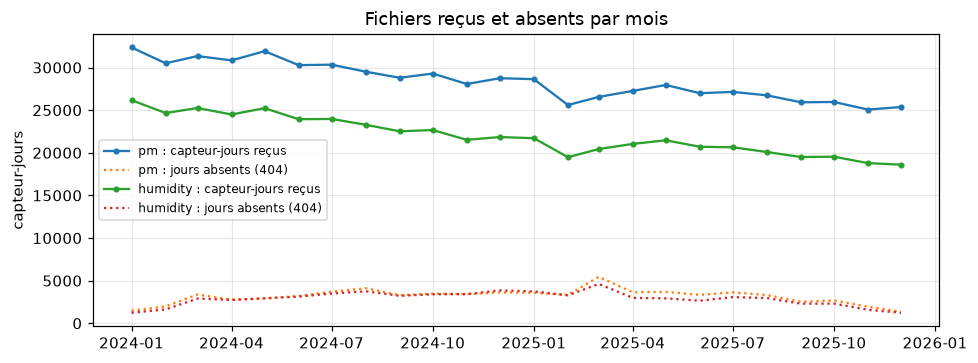

In [7]:
per_month = (
    latest.filter(pl.col("status") == "ok")
    .with_columns(pl.col("month").str.to_date())
    .group_by("kind", "month")
    .agg(jours_trouvés=pl.col("days_found").sum(), jours_absents=pl.col("days_absent").sum())
    .sort("month")
)
fig, ax = plt.subplots(figsize=(9, 3.4))
for kind, part in per_month.group_by("kind", maintain_order=True):
    ax.plot(part["month"], part["jours_trouvés"], marker=".", label=f"{kind[0]} : capteur-jours reçus")
    ax.plot(part["month"], part["jours_absents"], ls=":", label=f"{kind[0]} : jours absents (404)")
ax.set_ylabel("capteur-jours")
ax.set_title("Fichiers reçus et absents par mois")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_telechargement_par_mois.png")

- **Aucun échec** sur les 45 337 unités, ni au téléchargement ni à la conversion.
- 1 354 007 fichiers capteur-jour demandés en **3,05 h** (environ 123 requêtes par seconde, jamais plus de 8 à la fois),
  et 1 208 730 reçus (5,85 Go compressés).
- **10,7 %** des jours demandés n'existent pas (404).
- Les autres sources passent sans échec : EEA 582 fichiers (814 Mo), DWD 222 fichiers (343 Mo), Météo-France
  118 fichiers (2,0 Go reçus, dont on ne garde que **11 Mo**).
- Le disque a atteint environ 11 Go au plus fort, sous le budget de 20 Go, pour finir à **5,9 Go**. La conversion bronze
  a pris 12 min 35 s.

Les 10,7 % de jours absents correspondent aux bords de la fenêtre d'activité et aux pannes des capteurs. Ce n'est pas une
perte : on avait volontairement demandé large.

## 4. Le contrat bronze : qu'a-t-il trouvé ?

Chaque unité convertie passe par un contrat Pandera **strict** : aucune colonne en trop, des types exacts, des
identifiants non vides. Sans rien supprimer, on compte les textes **impossibles à convertir** (mis à vide et comptés),
les valeurs **non vides** dans les colonnes qu'on abandonne, les lignes qui appartiennent à un **autre capteur** que
celui du fichier, et les fichiers **illisibles**. Bronze ne juge pas les valeurs elles-mêmes (doublons, pics, humidité à
100 % restent là) : le nettoyage, ligne par ligne, c'est le rôle du notebook 03.

In [8]:
print(contracts.SensorCommunityPm.to_schema())
conv = bronze_manifest.frame()
audit_cols = [c for c in conv.columns if c.startswith("unparsed_")] + [
    "dropped_nonempty",
    "foreign_sensor_rows",
    "corrupt_files",
]
conv.group_by("kind").agg(
    lignes=pl.col("rows").sum(),
    **{c: pl.col(c).sum() for c in audit_cols},
    gzip_Mo=pl.col("raw_bytes").sum() / 1e6,
    parquet_Mo=pl.col("bronze_bytes").sum() / 1e6,
).with_columns(ratio_parquet_gzip=(pl.col("parquet_Mo") / pl.col("gzip_Mo")).round(2))

<Schema DataFrameSchema(
    columns={
        'sensor_id': <Schema Column(name=sensor_id, type=DataType(Int64))>
        'sensor_type': <Schema Column(name=sensor_type, type=DataType(String))>
        'location': <Schema Column(name=location, type=DataType(Int64))>
        'lat': <Schema Column(name=lat, type=DataType(Float64))>
        'lon': <Schema Column(name=lon, type=DataType(Float64))>
        'timestamp': <Schema Column(name=timestamp, type=DataType(Datetime(time_unit='us', time_zone=None)))>
        'P1': <Schema Column(name=P1, type=DataType(Float64))>
        'P2': <Schema Column(name=P2, type=DataType(Float64))>
    },
    checks=[],
    parsers=[],
    coerce=False,
    dtype=None,
    index=None,
    strict=True,
    name=SensorCommunityPm,
    ordered=False,
    unique_column_names=False,
    metadata=None, 
    add_missing_columns=False,
    on_missing_columns=None
)>


kind,lignes,unparsed_sensor_id,unparsed_sensor_type,unparsed_location,unparsed_lat,unparsed_lon,…,unparsed_P2,dropped_nonempty,foreign_sensor_rows,corrupt_files,gzip_Mo,parquet_Mo,ratio_parquet_gzip
str,i64,i64,i64,i64,i64,i64,…,i64,i64,i64,i64,f64,f64,f64
"""humidity""",289721376,0,0,0,0,0,…,0,0,0,0,2532.255139,2223.136379,0.88
"""pm""",377950455,0,0,0,0,0,…,7055,0,0,0,3321.214434,2916.301773,0.88


On en profite pour regarder les valeurs de `sensor_type` à l'intérieur des fichiers :

In [9]:
pm = pl.scan_parquet(B / "sensor_community" / "pm" / "*" / "*.parquet")
hp = pl.scan_parquet(B / "sensor_community" / "humidity" / "*" / "*.parquet")
print(
    "valeurs de sensor_type dans le contenu :",
    pm.select(pl.col("sensor_type").unique()).collect()["sensor_type"].to_list(),
    hp.select(pl.col("sensor_type").unique()).collect()["sensor_type"].to_list(),
)
pm.head(3).collect()

valeurs de sensor_type dans le contenu : ['SDS011'] ['SHT31', 'SHT85', 'BME280', 'DHT22', 'HTU21D', 'SHT30']


sensor_id,sensor_type,location,lat,lon,timestamp,P1,P2
i64,str,i64,f64,f64,datetime[μs],f64,f64
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:01:02,15.23,8.7
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:03:29,13.23,8.47
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:05:55,8.27,7.17


667,7 millions de lignes en tout (378 millions de mesures de particules, 290 millions de mesures météo), toutes conformes
au contrat : pas de fichier illisible, pas de ligne étrangère, rien dans les colonnes abandonnées. Le Parquet pèse 0,88
fois le gzip.

> **Vérification.** Le contrat a quand même trouvé un bug… dans notre propre code. Certains logiciels de capteurs écrivent
> une **virgule décimale** (`0,8` au lieu de `0.8`, sur les capteurs 96465 et 96466 fin 2025), et ces valeurs partaient
> à vide. On lit maintenant la virgule (92 818 valeurs récupérées), et on a retéléchargé puis reconverti les 57 unités
> concernées grâce au manifeste.

Il reste environ 21 700 textes vraiment non numériques (`unavailable`, `unknown`), mis à vide et comptés. Autre détail :
`sensor_type` est en **majuscules** dans les fichiers (`SDS011`) mais en minuscules dans leurs noms ; on le normalisera
au nettoyage.

## 5. Les stations de référence : PM2.5, PM10 et type de station

Pour chaque station appariée, on garde son point de mesure PM2.5 et, s'il existe, son point PM10 (le SDS011 mesure les
deux). On regarde les drapeaux de validité sur la période, puis le **type de station** (trafic, fond, industrielle)
croisé avec son **environnement** (urbain, périurbain, rural).

In [10]:
points = pl.read_parquet(REF / "eea_sampling_points.parquet")
eea = pl.scan_parquet(B / "eea" / "*" / "*" / "*.parquet")
flags = (
    eea.filter(pl.col("start").dt.date().is_between(settings.period.start, settings.period.end))
    .group_by("pollutant")
    .agg(
        heures=pl.len(),
        valides=pl.col("validity").is_in(settings.eea.valid_codes).mean().round(3),
        vérifiées=pl.col("verification").is_in(settings.eea.verified_codes).mean().round(3),
        sentinelle_999=(pl.col("value") == settings.eea.missing_sentinel).mean().round(3),
    )
    .collect()
)
print("points de mesure :", dict(points["pollutant"].value_counts().iter_rows()))
print(flags)
pairs.group_by("country", "station_type", "station_area").agg(
    paires=pl.len(), stations=pl.col("station_code").n_unique()
).sort("country", "paires", descending=[False, True])

points de mesure : {'pm10': 284, 'pm25': 298}
shape: (2, 5)
┌───────────┬─────────┬─────────┬───────────┬────────────────┐
│ pollutant ┆ heures  ┆ valides ┆ vérifiées ┆ sentinelle_999 │
│ ---       ┆ ---     ┆ ---     ┆ ---       ┆ ---            │
│ i32       ┆ u32     ┆ f64     ┆ f64       ┆ f64            │
╞═══════════╪═════════╪═════════╪═══════════╪════════════════╡
│ 6001      ┆ 5034624 ┆ 0.968   ┆ 1.0       ┆ 0.032          │
│ 5         ┆ 4764435 ┆ 0.981   ┆ 1.0       ┆ 0.019          │
└───────────┴─────────┴─────────┴───────────┴────────────────┘


country,station_type,station_area,paires,stations
str,str,str,u32,u32
"""DE""","""traffic""","""urban""",678,93
"""DE""","""background""","""urban""",357,73
"""DE""","""background""","""suburban""",170,48
"""DE""","""industrial""","""urban""",15,6
"""DE""","""industrial""","""suburban""",11,5
"""DE""","""background""","""rural-nearcity""",10,4
"""DE""","""industrial""","""rural-nearcity""",6,2
"""DE""","""background""","""rural-regional""",5,4
"""DE""","""background""","""rural""",4,4


298 points PM2.5 et 284 points PM10. Sur la période, 100 % des heures sont vérifiées, et 3,2 % des heures PM2.5 (1,9 %
en PM10) valent −999 avec un drapeau invalide. En Allemagne, 678 paires sur 1 257 sont près d'une station **trafic
urbaine** ; en France, 87 paires sur 142 sont près d'une station de **fond urbain**.

Une station trafic mesure au bord de la route. Un capteur citoyen à 1 km de là, sur un balcon, ne respire pas le même
air : c'est l'**erreur de représentativité**, qui ne vient pas du capteur et qu'on ne pourra pas corriger. On garde donc
le type de station jusqu'à la couche gold, et on découpera toutes les évaluations par type. Les −999 deviendront des
valeurs manquantes au nettoyage.

## 6. La météo officielle, notre solution de secours pour l'humidité

L'humidité est la variable clé de la correction, et on sait déjà que les sondes des capteurs saturent souvent
(section 7). On a donc cherché une humidité officielle pour chaque paire. Pour chaque station EEA appariée, on retient les
**2 stations météo officielles les plus proches** (à moins de 30 km) qui mesurent l'humidité et la température à l'heure :
le **DWD** (le service météo allemand) en Allemagne, **Météo-France** en France.

Le DWD publie la liste de ses stations, donc on choisit avant de télécharger. Météo-France ne la publie pas : on
télécharge les départements qui touchent le cercle de 30 km, on regarde quelles stations mesurent vraiment l'humidité, et
on garde les 2 plus proches.

In [11]:
frames = []
dwd_ref, mf_ref = REF / "weather_stations_dwd.parquet", REF / "weather_stations_meteo_france.parquet"
if dwd_ref.exists():
    frames.append(
        pl.read_parquet(dwd_ref)
        .select("sampling_point", "station_id", "distance_km", "rank")
        .with_columns(source=pl.lit("DWD"))
    )
if mf_ref.exists():
    frames.append(
        pl.read_parquet(mf_ref)
        .select("sampling_point", "station_id", "distance_km", "rank")
        .with_columns(source=pl.lit("Météo-France"))
    )
weather_links = pl.concat(frames)
official = pl.concat(
    [
        pl.scan_parquet(B / "dwd" / "*.parquet")
        .select("station_id", "time_utc", "temperature", "humidity")
        .with_columns(source=pl.lit("DWD"))
        .with_columns(
            [
                pl.when(pl.col(c) == settings.dwd.missing_sentinel).then(None).otherwise(pl.col(c)).alias(c)
                for c in ("temperature", "humidity")
            ]
        ),
        pl.scan_parquet(B / "meteo_france" / "*.parquet")
        .select("station_id", "time_utc", "temperature", "humidity")
        .with_columns(source=pl.lit("Météo-France")),
    ]
).collect()
coverage = official.group_by("source").agg(
    stations=pl.col("station_id").n_unique(),
    heures=pl.len(),
    humidité_présente=pl.col("humidity").is_not_null().mean().round(3),
    humidité_saturée=hum.is_saturated(pl.col("humidity"), SAT).mean().round(3),
)
print(coverage)
weather_links.group_by("source", "rank").agg(
    stations_EEA=pl.col("sampling_point").n_unique(),
    distance_médiane_km=pl.col("distance_km").median().round(1),
    distance_max_km=pl.col("distance_km").max().round(1),
).sort("source", "rank")

shape: (2, 5)
┌──────────────┬──────────┬─────────┬───────────────────┬──────────────────┐
│ source       ┆ stations ┆ heures  ┆ humidité_présente ┆ humidité_saturée │
│ ---          ┆ ---      ┆ ---     ┆ ---               ┆ ---              │
│ str          ┆ u32      ┆ u32     ┆ f64               ┆ f64              │
╞══════════════╪══════════╪═════════╪═══════════════════╪══════════════════╡
│ DWD          ┆ 222      ┆ 3830631 ┆ 0.996             ┆ 0.017            │
│ Météo-France ┆ 85       ┆ 1454649 ┆ 1.0               ┆ 0.028            │
└──────────────┴──────────┴─────────┴───────────────────┴──────────────────┘


source,rank,stations_EEA,distance_médiane_km,distance_max_km
str,i64,u32,f64,f64
"""DWD""",1,240,7.4,23.6
"""DWD""",2,227,17.8,29.9
"""Météo-France""",1,58,6.5,25.7
"""Météo-France""",2,57,13.1,29.8


Les stations météo ont été choisies d'après leur distance à la station EEA, alors que l'humidité servira à corriger le
**capteur**. On recalcule donc, pour chaque paire, la distance capteur → station météo (`pair_weather.parquet`). En
plaine, l'humidité relative change peu sur quelques dizaines de kilomètres, mais un relief, un fleuve ou une ville plus
chaude (où l'humidité relative est plus basse) peuvent la modifier.

paires sans station météo : 0
paires dont la station de rang 2 est plus proche du capteur que celle de rang 1 : 70


source,weather_rank,paires,médiane_km,q90_km,max_km
str,i64,u32,f64,f64,f64
"""dwd""",1,1257,6.4,12.8,25.1
"""dwd""",2,1230,15.6,23.5,31.8
"""meteo_france""",1,142,6.5,9.2,26.7
"""meteo_france""",2,140,12.6,27.5,29.8


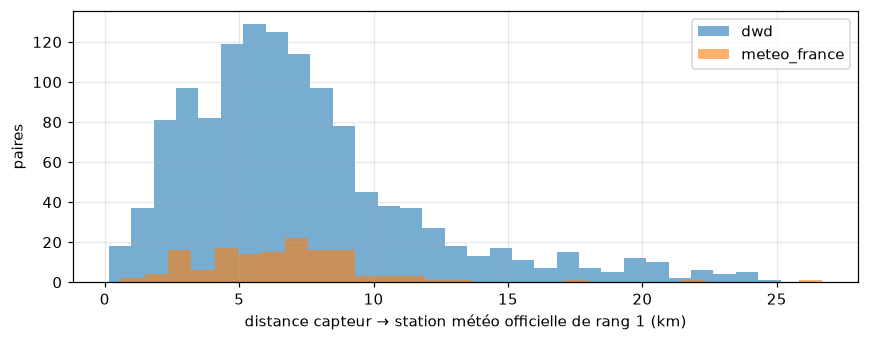

In [12]:
pair_weather = pl.read_parquet(REF / "pair_weather.parquet")
rank1 = pair_weather.filter(pl.col("weather_rank") == 1)
rank2 = pair_weather.filter(pl.col("weather_rank") == 2).select("sensor_id", km2="sensor_weather_km")
closer2 = rank1.join(rank2, on="sensor_id").filter(pl.col("km2") < pl.col("sensor_weather_km")).height
print(f"paires sans station météo : {pairs.join(pair_weather, on='sensor_id', how='anti').height}")
print(f"paires dont la station de rang 2 est plus proche du capteur que celle de rang 1 : {closer2}")
fig, ax = plt.subplots(figsize=(8, 3.2))
for (source,), part in rank1.group_by("source", maintain_order=True):
    ax.hist(part["sensor_weather_km"], bins=30, alpha=0.6, label=source)
ax.set_xlabel("distance capteur → station météo officielle de rang 1 (km)")
ax.set_ylabel("paires")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distance_capteur_meteo.png")
pair_weather.group_by("source", "weather_rank").agg(
    paires=pl.col("sensor_id").n_unique(),
    médiane_km=pl.col("sensor_weather_km").median().round(1),
    q90_km=pl.col("sensor_weather_km").quantile(0.9).round(1),
    max_km=pl.col("sensor_weather_km").max().round(1),
).sort("source", "weather_rank")

Toutes les stations EEA (240 en Allemagne, 58 en France) ont au moins une station météo officielle à moins de 30 km :
**aucune paire n'est privée d'humidité de secours**. Le DWD fournit 222 stations, avec 99,6 % d'heures renseignées ;
côté Météo-France, on garde 85 stations (sur les 195 qui mesurent l'humidité dans les départements lus). La station de
rang 1 est à **6,4 km** du capteur en médiane côté DWD, 6,5 km côté Météo-France ; 90 % des paires sont à moins de 12,8 et
9,2 km, et la plus lointaine à 26,7 km. Pour **70 paires**, la station de rang 2 est plus proche du capteur que celle de
rang 1. Les stations officielles saturent elles aussi, mais rarement : 1,7 % des heures DWD et 2,8 % des heures
Météo-France.

Au nettoyage, on prendra donc la station météo la plus proche **du capteur**, pas de la station EEA, et la distance
capteur ↔ station météo deviendra une variable du modèle.

### 6.1 Les stations météo sont-elles vraiment en UTC ?

Les deux services annoncent des heures UTC. Après la surprise de l'EEA, on a préféré vérifier. On utilise les
**températures** des sondes des capteurs (dont on sait que l'horloge est en UTC), moyennées sur 10 minutes, et on cherche
le décalage $\delta$ (en minutes) qui maximise la corrélation entre la valeur officielle à l'instant $t$ et la sonde à
l'instant $t + \delta$ :

$$
\delta^\star = \arg\max_{\delta}\ \operatorname{corr}\big(T_{\text{officielle}}(t),\ T_{\text{sonde}}(t+\delta)\big)
$$

où $T$ désigne la température et $\delta^\star$ le meilleur décalage. On prend les sondes à moins de 12 km de leur
station météo, en janvier, février, juillet et août des deux années, et seulement les mois où la corrélation dépasse 0,85.

> **Vérification.** L'astuce, c'est de comparer les saisons. Si un service horodatait en heure légale, $\delta^\star$
> sauterait d'une heure entre l'hiver (UTC+1) et l'été (UTC+2). Avec une horloge en UTC, l'écart hiver − été, calculé
> sonde par sonde, doit rester proche de 0. Un petit $\delta^\star$ positif est normal : le boîtier du capteur se
> réchauffe et se refroidit avec un temps de retard.

In [13]:
step, max_off = settings.weather.clock_check_step_min, settings.weather.clock_check_max_offset_min
offsets = list(range(-max_off, max_off + 1, step))
probe_site = humidity_probes.select("sensor_id", "location_id").join(
    pairs.select("location_id", "sampling_point"), on="location_id"
)
links = (
    probe_site.join(weather_links.filter(pl.col("rank") == 1), on="sampling_point")
    .unique("sensor_id")
    .filter(pl.col("distance_km") < 12)  # close enough for the temperatures to move together
    .sort("distance_km")
)
seasons = {1: "hiver", 2: "hiver", 7: "été", 8: "été"}
rows = []
for source, n_probes in (("DWD", 25), ("Météo-France", 40)):
    for rec in links.filter(pl.col("source") == source).head(n_probes).iter_rows(named=True):
        ref_all = official.filter(
            pl.col("source") == source, pl.col("station_id") == rec["station_id"]
        ).drop_nulls("temperature")
        probe = pl.read_parquet(
            B / "sensor_community" / "humidity" / str(rec["sensor_id"]) / "*.parquet",
            columns=["timestamp", "temperature"],
        )
        probe = probe.filter(pl.col("temperature").is_between(-40, 60))
        for (year, month), part in probe.group_by(
            pl.col("timestamp").dt.year().alias("year"), pl.col("timestamp").dt.month().alias("month")
        ):
            if month not in seasons or part.height < 2000:
                continue
            series = ten_minute_means(part, "timestamp", "temperature", step).collect()
            reference = ref_all.filter(
                pl.col("time_utc").dt.year() == year, pl.col("time_utc").dt.month() == month
            ).select(time="time_utc", value="temperature")
            corr = (
                offset_correlation(series, reference, offsets).drop_nulls().sort("pearson_r", descending=True)
            )
            if corr.height and corr["pearson_r"][0] > 0.85:
                rows.append(
                    {
                        "source": source,
                        "saison": seasons[month],
                        "sensor_id": rec["sensor_id"],
                        "best_offset_min": corr["offset_min"][0],
                        "r": corr["pearson_r"][0],
                    }
                )
clock = pl.DataFrame(rows)
per_probe = (
    clock.group_by("source", "sensor_id", "saison")
    .agg(pl.col("best_offset_min").median())
    .pivot(on="saison", index=["source", "sensor_id"], values="best_offset_min")
    .drop_nulls()
    .with_columns(hiver_moins_été=pl.col("hiver") - pl.col("été"))
)
print(
    per_probe.group_by("source").agg(
        sondes=pl.len(),
        écart_médian_min=pl.col("hiver_moins_été").median(),
        q25=pl.col("hiver_moins_été").quantile(0.25),
        q75=pl.col("hiver_moins_été").quantile(0.75),
    )
)
clock.group_by("source", "saison").agg(
    mois_sondes=pl.len(),
    sondes=pl.col("sensor_id").n_unique(),
    décalage_médian_min=pl.col("best_offset_min").median(),
    q25=pl.col("best_offset_min").quantile(0.25),
    q75=pl.col("best_offset_min").quantile(0.75),
    r_médian=pl.col("r").median().round(3),
).sort("source", "saison")

shape: (2, 5)
┌──────────────┬────────┬──────────────────┬───────┬──────┐
│ source       ┆ sondes ┆ écart_médian_min ┆ q25   ┆ q75  │
│ ---          ┆ ---    ┆ ---              ┆ ---   ┆ ---  │
│ str          ┆ u32    ┆ f64              ┆ f64   ┆ f64  │
╞══════════════╪════════╪══════════════════╪═══════╪══════╡
│ DWD          ┆ 15     ┆ 5.0              ┆ -15.0 ┆ 30.0 │
│ Météo-France ┆ 25     ┆ 0.0              ┆ -20.0 ┆ 25.0 │
└──────────────┴────────┴──────────────────┴───────┴──────┘


source,saison,mois_sondes,sondes,décalage_médian_min,q25,q75,r_médian
str,str,u32,u32,f64,f64,f64,f64
"""DWD""","""hiver""",59,20,-10.0,-20.0,0.0,0.961
"""DWD""","""été""",56,18,0.0,-40.0,10.0,0.952
"""Météo-France""","""hiver""",86,31,20.0,0.0,40.0,0.96
"""Météo-France""","""été""",79,28,20.0,0.0,50.0,0.941


Les corrélations sont très élevées (r médian entre 0,94 et 0,96). Sonde par sonde, l'écart entre le décalage d'hiver et
celui d'été vaut **0 min** pour Météo-France (25 sondes) et **5 min** pour le DWD (15 sondes), avec un intervalle
interquartile de −20 à +30 min. Aucun saut d'une heure, donc : les deux services sont bien en UTC.

Le décalage absolu est d'environ 0 pour le DWD et de +20 min pour Météo-France, sans doute à cause de la façon dont la
valeur horaire est mesurée et de l'inertie du boîtier. Comme il reste bien en dessous d'une heure, il ne change rien à la
jointure horaire. Notre premier essai, avec 12 sondes et deux mois, donnait +70 / +30 min : l'échantillon était trop
petit, d'où ce test élargi.

## 7. Le risque n°1 : l'humidité saturée des sondes bon marché

Quelle part des mesures d'humidité des sondes est vraiment utilisable ? Pour répondre, on donne un **statut** à chaque
mesure (`transform/humidity.py`, seuils dans la configuration) :

| statut | règle | exemple réel |
|---|---|---|
| manquante | vide ou `NaN` | BME280 qui renvoie `NaN` |
| hors bornes | humidité < 0 ou > 100 % | BME280 à 255 ou 655,35 (débordement d'entier), HTU21D à −6 ou 119 % |
| **figée basse** | humidité < 5 % (`humidity.floor_pct`) | DHT22 bloquée à exactement 1,0 % |
| **saturée** | humidité ≥ 99,9 % (`humidity.saturation_pct`) | sonde mouillée bloquée à 100 % |
| utilisable | le reste | |

Le seuil de 5 % vient des stations officielles : sur 5,27 millions d'heures, elles ne descendent sous 5 % que 9 fois.
Une sonde à 1 % est donc en panne, pas dans un air exceptionnellement sec.

> **Vérification : le piège du `NaN`.** `NaN` (*Not a Number*, une valeur flottante « non définie », différente d'un
> vide) est classé par Polars **au-dessus** de tous les nombres : `NaN >= 99.9` renvoie vrai. Sans traitement explicite,
> les 1,9 million de `NaN` des BME280 auraient été comptés comme saturés. Un test unitaire couvre ce cas.

Pourquoi tant de précautions ? La croissance des particules dans l'air humide se corrige avec un facteur

$$
C(\text{HR}) = 1 + \frac{\kappa/\rho}{\frac{100}{\text{HR}} - 1}
$$

où HR est l'humidité relative en %, $\kappa$ l'**hygroscopicité** des particules (leur capacité à absorber l'eau) et
$\rho$ un rapport de densités. Ce facteur **explose** quand HR approche 100 % : une humidité saturée prise au sérieux
ferait exploser la correction.

On mesure d'abord la part de chaque statut par type de sonde, sur toute la couche bronze.

In [14]:
H = settings.humidity
by_type = hum.status_shares(hp, ["sensor_type"], H).collect()
by_type.with_columns(pl.col("^.*_share$").round(4)).sort("n", descending=True)

sensor_type,saturated_share,stuck_share,stuck_low_share,out_of_range_share,usable_share,n_missing,n
str,f64,f64,f64,f64,f64,u32,u32
"""DHT22""",0.5349,0.0051,0.0684,0.0,0.3917,115142,168084111
"""BME280""",0.3051,0.0001,0.0084,0.0001,0.6863,1928754,112323885
"""SHT31""",0.0869,0.0,0.0,0.0,0.9131,1,4556385
"""HTU21D""",0.0004,0.0,0.0139,0.4351,0.5507,0,1515141
"""SHT30""",0.0151,0.0,0.0,0.0,0.9849,2,1058099
"""SHT85""",0.0062,0.0,0.0,0.0,0.9938,0,139856


Puis mois par mois, en comparant aux stations officielles :

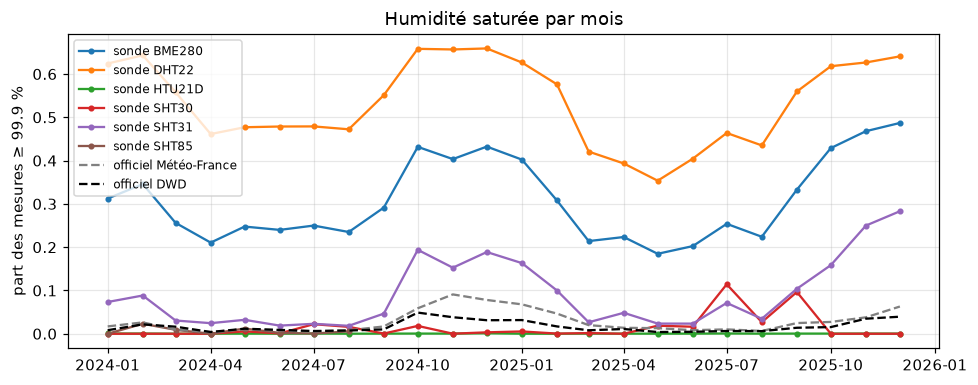

In [15]:
by_month = hum.status_shares(
    hp.with_columns(month=pl.col("timestamp").dt.truncate("1mo")), ["sensor_type", "month"], H
).collect()
official_month = (
    official.with_columns(month=pl.col("time_utc").dt.truncate("1mo"))
    .group_by("source", "month")
    .agg(saturated_share=hum.is_saturated(pl.col("humidity"), SAT).mean())
    .sort("month")
)
fig, ax = plt.subplots(figsize=(9, 3.6))
for (sensor_type,), part in by_month.filter(pl.col("n") > 10_000).group_by(
    "sensor_type", maintain_order=True
):
    if part.height > 2:
        ax.plot(part["month"], part["saturated_share"], marker=".", label=f"sonde {sensor_type}")
for (source,), part in official_month.group_by("source", maintain_order=True):
    ax.plot(
        part["month"],
        part["saturated_share"],
        ls="--",
        color="k" if source == "DWD" else "grey",
        label=f"officiel {source}",
    )
ax.set_ylabel(f"part des mesures ≥ {SAT:g} %")
ax.set_title("Humidité saturée par mois")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_humidite_saturee_par_mois.png")

On regarde enfin de plus près les valeurs **figées basses** et **hors bornes**. Une valeur répétée des millions de fois
à l'identique, ce n'est plus une mesure, c'est le signe d'un composant bloqué.

In [16]:
odd = (
    hp.with_columns(status=hum.reading_status(pl.col("humidity"), H))
    .filter(pl.col("status").is_in([hum.STUCK_LOW, hum.OUT_OF_RANGE]))
    .group_by("sensor_type", "status", "humidity")
    .agg(mesures=pl.len(), sondes=pl.col("sensor_id").n_unique())
    .collect()
    .sort("mesures", descending=True)
)
print(
    odd.group_by("sensor_type", "status")
    .agg(mesures=pl.col("mesures").sum())
    .sort("mesures", descending=True)
)
odd.head(8)

shape: (6, 3)
┌─────────────┬──────────────┬──────────┐
│ sensor_type ┆ status       ┆ mesures  │
│ ---         ┆ ---          ┆ ---      │
│ str         ┆ str          ┆ u32      │
╞═════════════╪══════════════╪══════════╡
│ DHT22       ┆ stuck_low    ┆ 11490191 │
│ BME280      ┆ stuck_low    ┆ 944555   │
│ HTU21D      ┆ out_of_range ┆ 659236   │
│ HTU21D      ┆ stuck_low    ┆ 21058    │
│ BME280      ┆ out_of_range ┆ 9757     │
│ DHT22       ┆ out_of_range ┆ 499      │
└─────────────┴──────────────┴──────────┘


sensor_type,status,humidity,mesures,sondes
str,str,f64,u32,u32
"""DHT22""","""stuck_low""",1.0,11220291,166
"""BME280""","""stuck_low""",0.0,937724,63
"""HTU21D""","""out_of_range""",118.99,439785,4
"""HTU21D""","""out_of_range""",-6.0,116409,2
"""DHT22""","""stuck_low""",0.0,24045,7
"""DHT22""","""stuck_low""",1.4,10558,142
"""BME280""","""out_of_range""",-1.0,9561,2
"""DHT22""","""stuck_low""",1.8,7241,139


Le constat est assez brutal. Seules **39,7 %** des mesures DHT22 et **68,6 %** des mesures BME280 sont utilisables,
contre 91 à 99 % pour les sondes Sensirion (SHT30/31/85), qui sont rares (21 sondes). La saturation touche **53,5 %** des
mesures DHT22 et **30,5 %** des BME280, et elle suit la saison humide : 66 % pour les DHT22 d'octobre à décembre 2024,
contre 35 % en mai 2025, alors que les stations officielles ne dépassent jamais 9 % (Météo-France, novembre 2024).

On a aussi trouvé des défauts qu'on n'attendait pas : **11,2 millions de mesures DHT22 valent exactement 1,0 %**
(166 sondes), et 0,94 million de mesures BME280 valent exactement 0 % (63 sondes). Sur ces dernières lignes, la sonde
indique aussi −33 °C et 303 hPa : la puce ne répond tout simplement plus. Bref, une humidité locale fiable sera
l'exception plutôt que la règle, surtout en hiver et avec les DHT22.

### 7.1 Sondes « mortes » ou pannes passagères ?

Une sonde qui sature de temps en temps reste-t-elle fiable le reste du temps ? Les deux cas ne se traitent pas de la même
façon : jeter tout le mois d'une sonde saine gaspillerait des heures utiles, mais garder les heures « normales » d'une
sonde en train de mourir ferait entrer des valeurs fausses.

On appelle **heure en défaut** une heure où plus de la moitié des mesures ne sont pas utilisables. Pour chaque
**mois-sonde**, on calcule la part d'heures en défaut :

$$
s_{\text{mois}} = \frac{\text{heures en défaut}}{\text{heures avec au moins une mesure d'humidité}}
$$

Au-delà d'un seuil $X$ (`humidity.dead_month_share`), on considère la sonde comme morte ce mois-là et on écarte tout le
mois ; en dessous, on n'écarte que les heures en défaut. Pour choisir $X$, on regarde la distribution de
$s_{\text{mois}}$, puis on vérifie, contre la station météo officielle, si les heures **utilisables** restent justes
quand $s_{\text{mois}}$ augmente.

18,744 mois-sondes, 1126 sondes


tranche,mois_sondes,part
str,u32,f64
"""0 %""",4376,0.233
"""0–10 %""",1715,0.091
"""10–30 %""",1473,0.079
"""30–50 %""",1423,0.076
"""50–70 %""",1854,0.099
"""70–90 %""",2648,0.141
"""> 90 %""",5255,0.28


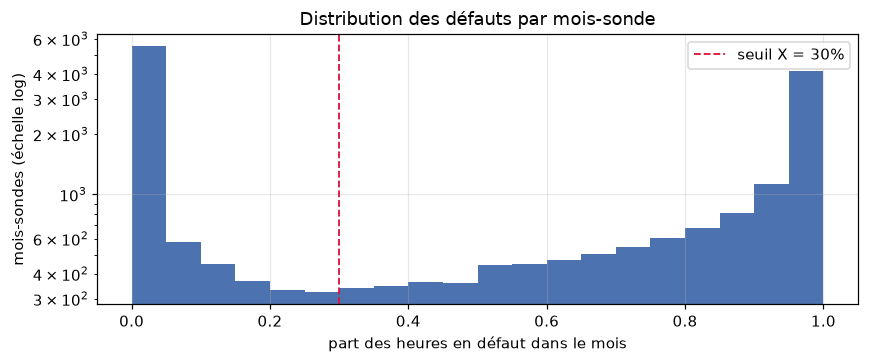

In [17]:
probe_hourly = hum.hourly_humidity(hp, H).collect()
monthly = hum.monthly_quality(probe_hourly).collect()
X = H.dead_month_share
edges = [i / 20 for i in range(21)]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(monthly["faulty_month_share"], bins=edges, color="#4C72B0")
ax.axvline(X, color="crimson", ls="--", lw=1.2, label=f"seuil X = {X:.0%}")
ax.set_yscale("log")
ax.set_xlabel("part des heures en défaut dans le mois")
ax.set_ylabel("mois-sondes (échelle log)")
ax.set_title("Distribution des défauts par mois-sonde")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_saturation_par_mois_sonde.png")
counts = (
    monthly.with_columns(
        tranche=pl.when(pl.col("faulty_month_share") == 0)
        .then(pl.lit("0 %"))
        .when(pl.col("faulty_month_share") <= 0.1)
        .then(pl.lit("0–10 %"))
        .when(pl.col("faulty_month_share") <= 0.3)
        .then(pl.lit("10–30 %"))
        .when(pl.col("faulty_month_share") <= 0.5)
        .then(pl.lit("30–50 %"))
        .when(pl.col("faulty_month_share") <= 0.7)
        .then(pl.lit("50–70 %"))
        .when(pl.col("faulty_month_share") <= 0.9)
        .then(pl.lit("70–90 %"))
        .otherwise(pl.lit("> 90 %"))
    )
    .group_by("tranche")
    .agg(mois_sondes=pl.len())
    .with_columns(part=(pl.col("mois_sondes") / pl.col("mois_sondes").sum()).round(3))
)
print(f"{monthly.height:,} mois-sondes, {monthly['sensor_id'].n_unique()} sondes")
counts.sort("tranche")

On compare maintenant les heures utilisables à l'humidité officielle, tranche par tranche de $s_{\text{mois}}$, et on
chiffre ce que chaque seuil $X$ permettrait de garder.

In [18]:
link1 = probe_site.join(weather_links.filter(pl.col("rank") == 1), on="sampling_point").unique("sensor_id")
official_hourly = (
    link1.select("sensor_id", "station_id", "source")
    .join(
        official.select("source", "station_id", hour="time_utc", official_humidity="humidity"),
        on=["source", "station_id"],
    )
    .select("sensor_id", "hour", "official_humidity")
    .drop_nulls()
)
both = (
    probe_hourly.join(official_hourly, on=["sensor_id", "hour"], how="inner")
    .with_columns(month=pl.col("hour").dt.truncate("1mo").dt.date())
    .join(monthly.select("sensor_id", "month", "faulty_month_share"), on=["sensor_id", "month"])
)
gap = pl.col("humidity") - pl.col("official_humidity")
agreement = (
    both.filter(~pl.col("faulty"), pl.col("sensor_type").is_in(["DHT22", "BME280"]))
    .with_columns(s_mois=(pl.col("faulty_month_share") * 10).floor().clip(0, 9) / 10)
    .group_by("sensor_type", "s_mois")
    .agg(heures=pl.len(), biais=gap.median().round(1), corr=pl.corr("humidity", "official_humidity").round(2))
    .sort("sensor_type", "s_mois")
)
sensitivity = pl.concat(
    [
        hum.classify_months(monthly, x)
        .select(
            X_candidat=pl.lit(x),
            part_mois_morts=(pl.col("status") == hum.DEAD).mean().round(3),
            heures_récupérables=pl.col("recoverable_hours").sum(),
            part_récupérable=(pl.col("recoverable_hours").sum() / pl.col("hours").sum()).round(3),
        )
        .collect()
        for x in (0.1, 0.2, 0.3, 0.4, 0.5, 0.7)
    ]
)
print(sensitivity)
agreement.pivot(on="sensor_type", index="s_mois", values=["biais", "corr", "heures"])

shape: (6, 4)
┌────────────┬─────────────────┬─────────────────────┬──────────────────┐
│ X_candidat ┆ part_mois_morts ┆ heures_récupérables ┆ part_récupérable │
│ ---        ┆ ---             ┆ ---                 ┆ ---              │
│ f64        ┆ f64             ┆ u32                 ┆ f64              │
╞════════════╪═════════════════╪═════════════════════╪══════════════════╡
│ 0.1        ┆ 0.675           ┆ 3850456             ┆ 0.321            │
│ 0.2        ┆ 0.631           ┆ 4301079             ┆ 0.359            │
│ 0.3        ┆ 0.596           ┆ 4618406             ┆ 0.385            │
│ 0.4        ┆ 0.56            ┆ 4906091             ┆ 0.409            │
│ 0.5        ┆ 0.521           ┆ 5163355             ┆ 0.431            │
│ 0.7        ┆ 0.422           ┆ 5643218             ┆ 0.471            │
└────────────┴─────────────────┴─────────────────────┴──────────────────┘


s_mois,biais_BME280,biais_DHT22,corr_BME280,corr_DHT22,heures_BME280,heures_DHT22
f64,f64,f64,f64,f64,u32,u32
0.0,-13.0,-10.0,0.68,0.54,2074058,1431614
0.1,-2.3,3.7,0.83,0.55,290472,134093
0.2,1.0,8.8,0.82,0.41,184474,114361
0.3,2.7,13.8,0.79,0.4,151589,117427
0.4,3.6,16.6,0.77,0.39,104465,136278
0.5,5.7,21.9,0.74,0.27,108487,147727
0.6,8.0,25.7,0.68,0.23,66601,145769
0.7,12.2,26.7,0.56,-0.05,49209,129500
0.8,15.4,27.3,0.56,-0.17,36457,98926


La distribution de $s_{\text{mois}}$ n'a pas deux bosses bien séparées comme on l'espérait : 24 % des mois-sondes n'ont
aucune heure en défaut, 27,8 % en ont plus de 90 %, et entre les deux, c'est entre 10 et 50 % que la densité est la plus
faible. C'est le tableau de comparaison avec la station officielle qui permet de trancher :

- tant que $0 < s_{\text{mois}} < 0{,}3$, les heures utilisables suivent bien l'humidité officielle (pour la BME280 : biais
  médian de −2,3 à +1,0 point, corrélation 0,82–0,83) ;
- à partir de 0,3, le biais grimpe (DHT22 : +13,8 points dans la tranche 0,3–0,4, +21,9 dans 0,5–0,6) et la corrélation
  des DHT22 tombe sous 0,4.

Une sonde qui commence à mourir ne se contente donc pas de saturer : même ses heures non saturées dérivent vers le haut.

On a retenu **X = 0,3**. Avec X = 0,1, on ne récupérait que 32,6 % des heures, en jetant des sondes encore justes ; avec
X = 0,5, on en gardait 43,4 %, mais avec 0,54 million d'heures douteuses en plus. À 0,3, on garde 38,9 % des heures, au
moment où la dérive devient nette. On sacrifie donc 0,54 million d'heures de sonde par rapport à X = 0,5. On a testé plus
tard la sensibilité du modèle à ce seuil (notebook 06) : l'effet est négligeable.

> **Remarque.** Même les mois **sans aucun défaut** lisent trop **sec** : 13 points sous l'humidité officielle pour la
> BME280, 9,6 points pour la DHT22, sans doute parce que l'électronique du boîtier réchauffe la sonde. « Fiable » ne veut
> donc pas dire « juste ».

Avec X = 0,3, on classe chaque sonde (saine, morte certains mois, morte toute la période) et on compte les heures qu'on
peut récupérer.

In [19]:
classified = hum.classify_months(monthly, X).collect()
status = hum.probe_status(classified).collect()
print("sondes par classe :")
print(
    status.group_by("sensor_type", "probe_class")
    .agg(sondes=pl.len())
    .pivot(on="probe_class", index="sensor_type", values="sondes")
    .fill_null(0)
    .sort("sensor_type")
)
hours = classified.select(
    heures_avec_mesure=pl.col("hours").sum(),
    perdues_mois_morts=pl.when(pl.col("status") == hum.DEAD).then(pl.col("hours")).otherwise(0).sum(),
    écartées_épisodiques=pl.when(pl.col("status") == hum.HEALTHY)
    .then(pl.col("faulty_hours"))
    .otherwise(0)
    .sum(),
    récupérables=pl.col("recoverable_hours").sum(),
)
print(hours.with_columns(part_récupérable=(pl.col("récupérables") / pl.col("heures_avec_mesure")).round(3)))
status.group_by("sensor_type", "probe_class").agg(
    sondes=pl.len(), heures=pl.col("hours").sum(), récupérables=pl.col("recoverable_hours").sum()
).with_columns(part_récupérable=(pl.col("récupérables") / pl.col("heures")).round(3)).sort(
    "sensor_type", "probe_class"
)

sondes par classe :
shape: (6, 4)
┌─────────────┬─────────────────────┬───────┬────────────────────────┐
│ sensor_type ┆ morte certains mois ┆ saine ┆ morte toute la période │
│ ---         ┆ ---                 ┆ ---   ┆ ---                    │
│ str         ┆ u32                 ┆ u32   ┆ u32                    │
╞═════════════╪═════════════════════╪═══════╪════════════════════════╡
│ BME280      ┆ 230                 ┆ 150   ┆ 93                     │
│ DHT22       ┆ 143                 ┆ 112   ┆ 372                    │
│ HTU21D      ┆ 2                   ┆ 1     ┆ 2                      │
│ SHT30       ┆ 1                   ┆ 3     ┆ 0                      │
│ SHT31       ┆ 5                   ┆ 11    ┆ 0                      │
│ SHT85       ┆ 0                   ┆ 1     ┆ 0                      │
└─────────────┴─────────────────────┴───────┴────────────────────────┘
shape: (1, 5)
┌────────────────────┬────────────────────┬──────────────────────┬──────────────┬──────────────────┐

sensor_type,probe_class,sondes,heures,récupérables,part_récupérable
str,str,u32,u32,u32,f64
"""BME280""","""morte certains mois""",230,2586849,1380301,0.534
"""BME280""","""morte toute la période""",93,835549,0,0.0
"""BME280""","""saine""",150,1264301,1250568,0.989
"""DHT22""","""morte certains mois""",143,1744390,584113,0.335
"""DHT22""","""morte toute la période""",372,4081721,0,0.0
"""DHT22""","""saine""",112,1176282,1167031,0.992
"""HTU21D""","""morte certains mois""",2,20815,7212,0.346
"""HTU21D""","""morte toute la période""",2,21426,0,0.0
"""HTU21D""","""saine""",1,14285,14285,1.0


Sur les 1 126 sondes qui ont des mesures : côté **DHT22**, 118 saines, 141 mortes certains mois et **368 mortes pendant
toute la période (59 %)** ; côté **BME280**, 150 saines, 230 mortes certains mois et 93 mortes toute la période (20 %) ;
côté Sensirion, 15 saines sur 21. Sur 11,99 millions d'heures-sondes, **7,10 millions sont perdues** dans les mois morts et
**4,66 millions récupérables (38,9 %)**. Moins de 4 heures de sonde sur 10 sont donc exploitables.

### 7.2 L'âge de la sonde joue-t-il ?

Si les sondes meurent en vieillissant, l'âge du capteur devient une variable intéressante. Le problème, c'est que l'âge
n'est publié nulle part. On l'a estimé à partir des identifiants, attribués dans l'ordre d'enregistrement : avec des
listings d'archive deux fois par an depuis 2016, on connaît le plus grand identifiant existant à chaque date. Une sonde
existait donc au plus tard à la première date où ce maximum dépasse son identifiant (à environ 6 mois près avant 2024,
1 mois ensuite). On croise ensuite l'âge avec la part de mois morts.

sondes sans date d'enregistrement : 0


sensor_type,age,sondes,mois_sondes,part_mois_morts,défaut_épisodique,heures_récupérables
str,str,u32,u32,f64,f64,u32
"""BME280""","""<1""",169,1206,0.193,0.03,582352
"""BME280""","""1-2""",127,895,0.398,0.047,334765
"""BME280""","""2-4""",183,1645,0.486,0.058,520495
"""BME280""","""4-6""",222,2304,0.45,0.056,789918
"""BME280""",""">=6""",113,1320,0.492,0.063,403339
"""DHT22""","""<1""",45,345,0.513,0.018,90540
"""DHT22""","""1-2""",54,343,0.475,0.035,108356
"""DHT22""","""2-4""",165,1096,0.589,0.031,281265
"""DHT22""","""4-6""",426,4145,0.758,0.038,615506


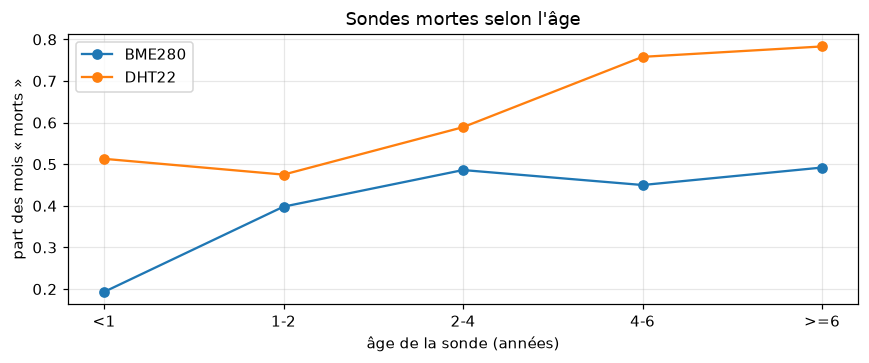

In [20]:
registrations = pl.read_parquet(REF / "sensor_registrations.parquet")
aged = (
    classified.join(registrations, on="sensor_id", how="left")
    .with_columns(age_years=(pl.col("month") - pl.col("registered_by")).dt.total_days() / 365.25)
    .with_columns(
        age=hum.age_class(pl.col("age_years").clip(lower_bound=0), settings.humidity.age_breaks_years)
    )
)
print(
    "sondes sans date d'enregistrement :",
    aged.filter(pl.col("registered_by").is_null())["sensor_id"].n_unique(),
)
by_age = (
    aged.filter(pl.col("age").is_not_null())
    .group_by("sensor_type", "age")
    .agg(
        sondes=pl.col("sensor_id").n_unique(),
        mois_sondes=pl.len(),
        part_mois_morts=(pl.col("status") == hum.DEAD).mean().round(3),
        défaut_épisodique=(
            pl.when(pl.col("status") == hum.HEALTHY).then(pl.col("faulty_hours")).sum()
            / pl.when(pl.col("status") == hum.HEALTHY).then(pl.col("hours")).sum()
        ).round(3),
        heures_récupérables=pl.col("recoverable_hours").sum(),
    )
    .filter(pl.col("sondes") >= 5)
    .sort("sensor_type", pl.col("age").cast(pl.Enum(["<1", "1-2", "2-4", "4-6", ">=6"])))
)
fig, ax = plt.subplots(figsize=(8, 3.4))
for (sensor_type,), part in by_age.group_by("sensor_type", maintain_order=True):
    if part.height >= 3:
        ax.plot(part["age"], part["part_mois_morts"], marker="o", label=sensor_type)
ax.set_xlabel("âge de la sonde (années)")
ax.set_ylabel("part des mois « morts »")
ax.set_title("Sondes mortes selon l'âge")
if ax.lines:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sondes_mortes_par_age.png")
by_age

Pour la DHT22, la part de mois morts passe de 47–50 % la première année à **75–78 % après 4 ans** ; pour la BME280, de
**19 %** la première année à 40–49 % ensuite. Une DHT22 de plus de 4 ans n'a pratiquement plus d'humidité locale. On
ajoute donc l'âge estimé du capteur aux variables du modèle.

### 7.3 La preuve : sonde saturée contre station officielle, à la même heure

Il restait une question : quand une sonde affiche 100 %, est-ce du brouillard ou une panne ? On compare, heure par heure,
l'humidité affichée par la sonde (défauts compris) à celle de la station météo officielle de sa paire, à la même heure
UTC. À gauche, toutes les heures ; à droite, seulement celles où la sonde est saturée. Si c'était du brouillard, la
station officielle devrait elle aussi être proche de 100 %.

heures comparables : 11,541,848 | dont sonde en défaut « saturée » : 5,110,874
quand la sonde est saturée, la station officielle l'est aussi : 2.1%
… elle mesure moins de 90 % : 63.3% | moins de 80 % : 35.1%
médiane de l'humidité officielle quand la sonde est saturée : 85 %


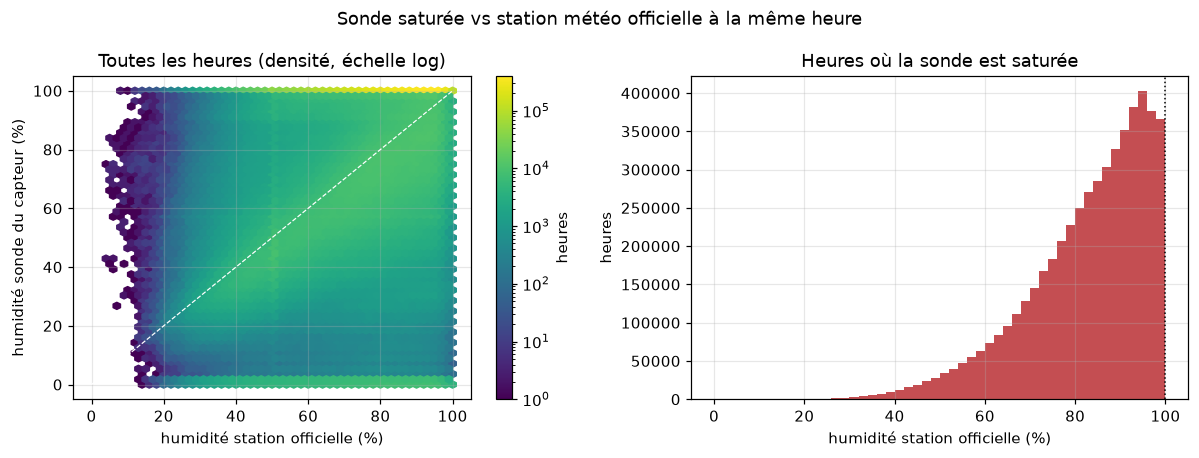

In [21]:
ghost = hum.saturated_vs_official(probe_hourly, official_hourly, SAT)
print(f"heures comparables : {both.height:,} | dont sonde en défaut « saturée » : {ghost.height:,}")
official_rh = ghost["official_humidity"]
also_saturated = ghost["official_saturated"].mean()
print(f"quand la sonde est saturée, la station officielle l'est aussi : {also_saturated:.1%}")
below90, below80 = (official_rh < 90).mean(), (official_rh < 80).mean()
print(f"… elle mesure moins de 90 % : {below90:.1%} | moins de 80 % : {below80:.1%}")
print(f"médiane de l'humidité officielle quand la sonde est saturée : {official_rh.median():.0f} %")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
claimed = both.drop_nulls("raw_humidity")
hb = axes[0].hexbin(
    claimed["official_humidity"],
    claimed["raw_humidity"],
    gridsize=50,
    bins="log",
    cmap="viridis",
    extent=(0, 100, 0, 100),
)
axes[0].plot([0, 100], [0, 100], color="w", lw=0.8, ls="--")
axes[0].set_xlabel("humidité station officielle (%)")
axes[0].set_ylabel("humidité sonde du capteur (%)")
axes[0].set_title("Toutes les heures (densité, échelle log)")
fig.colorbar(hb, ax=axes[0], label="heures")
axes[1].hist(ghost["official_humidity"], bins=50, range=(0, 100), color="#C44E52")
axes[1].axvline(SAT, color="k", ls=":", lw=1)
axes[1].set_xlabel("humidité station officielle (%)")
axes[1].set_ylabel("heures")
axes[1].set_title("Heures où la sonde est saturée")
fig.suptitle("Sonde saturée vs station météo officielle à la même heure")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_saturation_vs_officiel.png")

Sur 11,5 millions d'heures comparables, 5,11 millions sont des heures où la sonde est saturée. Pendant ces heures, la
station officielle n'est saturée que **2,1 %** du temps ; elle est **sous 90 % dans 63 % des cas**, sous 80 % dans 35 %,
avec une médiane de **85 %**. Sur le graphique de gauche, la bande horizontale à 100 % s'étale sur toutes les humidités
officielles, de 20 à 100 %.

La sonde affiche donc 100 % quel que soit l'air réel : c'est bien une **panne**, pas du brouillard. L'air humide (85 % en
médiane) sert de déclencheur : la sonde se mouille, puis ne sèche plus. On a donc décidé de considérer toute humidité
saturée ou figée comme **manquante**, jamais comme une vraie valeur, et de faire de l'humidité **officielle** l'entrée
principale du modèle. La sonde devient une variable secondaire.

## 8. Des capteurs qui déménagent

La distance capteur ↔ station a été calculée à partir de la position la plus récente. Mais un capteur a très bien pu
déménager pendant la période. Pour le savoir, on liste, pour chaque capteur de particules, les positions distinctes qu'on
trouve dans les fichiers bruts, et la distance entre la première et la dernière.

In [22]:
positions = position_history(pm.select("sensor_id", "location", "lat", "lon", "timestamp")).collect()
moved = (
    positions.group_by("sensor_id")
    .agg(
        positions=pl.len(),
        sites=pl.col("location").n_unique(),
        lat0=pl.col("lat").first(),
        lon0=pl.col("lon").first(),
        lat1=pl.col("lat").last(),
        lon1=pl.col("lon").last(),
    )
    .filter(pl.col("positions") > 1)
    .with_columns(
        déplacement_km=haversine_km(pl.col("lat0"), pl.col("lon0"), pl.col("lat1"), pl.col("lon1")).round(2)
    )
)
print(f"capteurs PM avec plus d'une position : {moved.height} sur {positions['sensor_id'].n_unique()}")
moved.select("sensor_id", "positions", "sites", "déplacement_km").sort(
    "déplacement_km", descending=True
).head(10)

capteurs PM avec plus d'une position : 65 sur 1399


sensor_id,positions,sites,déplacement_km
i64,u32,u32,f64
84804,2,2,8452.76
36947,2,2,2386.67
10569,2,2,627.35
87524,4,3,370.22
86868,3,3,366.22
42694,3,2,177.17
9232,2,2,153.45
52206,2,2,114.84
68184,2,2,63.15


65 capteurs sur 1 399 ont plus d'une position : 23 ont bougé de moins de 100 m (coordonnées arrondies ou corrigées), 21
de 0,1 à 3 km, et **21 de plus de 3 km**. Le cas le plus étonnant est le capteur 84804, installé **à Hanoï**
(21,06° N ; 105,83° E) jusqu'au 5 septembre 2025, puis à Magdebourg. Le 36947, lui, a eu pendant 11 heures une position en
Russie, sans doute une erreur de saisie.

Sans rien faire, on aurait comparé 20 mois de pollution d'Hanoï à une station allemande. Au nettoyage (notebook 03), on
découpera donc les mesures par **segment de position**, et on ne gardera que les périodes où le capteur est réellement à
portée de sa station.

## Ce qu'il faut retenir

- **Téléchargement complet sans aucun échec** : 1,21 million de fichiers (5,85 Go) en 3 h 04, soit 667,7 millions de
  lignes en bronze. Les 10,7 % de jours absents étaient attendus.
- Le contrat bronze a repéré un bug de notre lecture (la virgule décimale), ce qui a permis de récupérer 92 818 valeurs.
- **L'humidité des sondes** : 53,5 % des mesures DHT22 et 30,5 % des BME280 sont saturées, seules **38,9 %** des
  heures-sondes sont récupérables (avec X = 0,3), et 59 % des DHT22 sont mortes toute la période.
- La preuve que c'est une panne : quand la sonde sature, la station officielle ne l'est que **2,1 %** du temps. L'humidité
  officielle (à 6,4 km en médiane, horloge UTC vérifiée) devient donc l'entrée principale.
- 21 capteurs ont déménagé de plus de 3 km pendant la période, d'où un découpage par position.